# 04 - Models

Question: can logistic regression and gradient-boosted trees beat the best baseline, scored on the validation split?

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv('../data.raw/weatherAUS.csv', parse_dates=['Date'])
d = df.dropna(subset=['RainTomorrow']).copy()
d['y'] = (d['RainTomorrow'] == 'Yes').astype(int)
d['Month'] = d['Date'].dt.month

train_end = d['Date'].quantile(0.8)
val_end = d['Date'].quantile(0.9)
train = d[d['Date'] <= train_end]
val = d[(d['Date'] > train_end) & (d['Date'] <= val_end)]

cat_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'Month']
num_cols = [c for c in d.select_dtypes('number').columns if c not in ['y', 'Month']]

X_train, y_train = train[num_cols + cat_cols], train['y']
X_val, y_val = val[num_cols + cat_cols], val['y']

In [2]:
numeric = Pipeline([
    ('fill', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
])

categorical = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

prep = ColumnTransformer([
    ('num', numeric, num_cols),
    ('cat', categorical, cat_cols),
])

print(X_train.shape, prep.fit_transform(X_train).shape)


(113796, 22) (113796, 147)


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def score(name, y_true, y_pred):
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }

logreg = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(max_iter=1000)),
])
logreg.fit(X_train, y_train)

logreg_balanced = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
logreg_balanced.fit(X_train, y_train)

results = pd.DataFrame([
    score('logreg', y_val, logreg.predict(X_val)),
    score('logreg balanced', y_val, logreg_balanced.predict(X_val)),
])
print(results.round(3))


             model  accuracy  precision  recall     f1
0           logreg     0.845      0.722   0.524  0.607
1  logreg balanced     0.789      0.526   0.783  0.629


In [6]:
from lightgbm import LGBMClassifier

to_category = {c: 'category' for c in cat_cols}
X_train_gbm = X_train.astype(to_category)
X_val_gbm = X_val.astype(to_category)

gbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)
gbm.fit(X_train_gbm, y_train)

gbm_balanced = LGBMClassifier(n_estimators=500, learning_rate=0.05, class_weight='balanced',
                              random_state=42, verbose=-1)
gbm_balanced.fit(X_train_gbm, y_train)

results = pd.DataFrame([
    score('gbm', y_val, gbm.predict(X_val_gbm)),
    score('gbm balanced', y_val, gbm_balanced.predict(X_val_gbm)),
])
print(results.round(3))


          model  accuracy  precision  recall     f1
0           gbm     0.861      0.753   0.582  0.656
1  gbm balanced     0.824      0.586   0.782  0.670


Finding: Both models beat both baselines on validation. LightGBM is best: accuracy 0.861 and F1 0.656 plain, or recall 0.782 and F1 0.670 with balanced weights. Logistic regression reaches F1 0.607 to 0.629.


Why it matters: The gain over a straight-line model is about 0.04 to 0.05 F1, so most of the signal is simple and the rest comes from combinations and missingness patterns. Balanced weights trade precision for recall without changing the model's underlying skill.

Decision: Take LightGBM to the test set. Which weighting to use depends on which mistake costs more.

Limit: No settings were tuned. The model scores higher on training rows (F1 0.734) than validation, so there is some overfitting. One validation period is a single sample of weather.

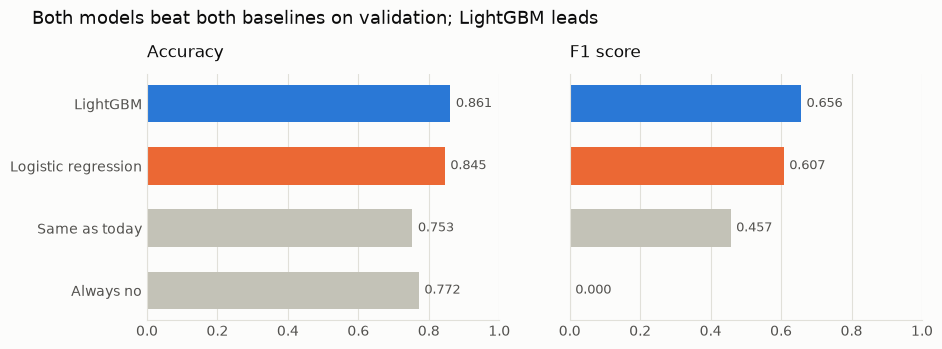

In [8]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import precision_recall_curve

BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#c3c2b7'
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e1e0d9'
Path('../figures').mkdir(exist_ok=True)

def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc='left', color=INK, fontsize=12, pad=12)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)


comparison = pd.DataFrame([
    score('Always no', y_val, pd.Series(0, index=y_val.index)),
    score('Same as today', y_val, (X_val['RainToday'] == 'Yes').astype(int)),
    score('Logistic regression', y_val, logreg.predict(X_val)),
    score('LightGBM', y_val, gbm.predict(X_val_gbm)),
]).set_index('model')
colours = [GREY, GREY, ORANGE, BLUE]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), facecolor=SURFACE, sharey=True)
for ax, metric, title in zip(axes, ['accuracy', 'f1'], ['Accuracy', 'F1 score']):
    bars = ax.barh(comparison.index, comparison[metric], color=colours, height=0.6)
    ax.bar_label(bars, fmt='{:.3f}', padding=4, color=MUTED, fontsize=9)
    style(ax, title)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
fig.suptitle('Both models beat both baselines on validation; LightGBM leads', x=0.01, ha='left',
             color=INK, fontsize=13, y=1.08)
fig.savefig('../figures/model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


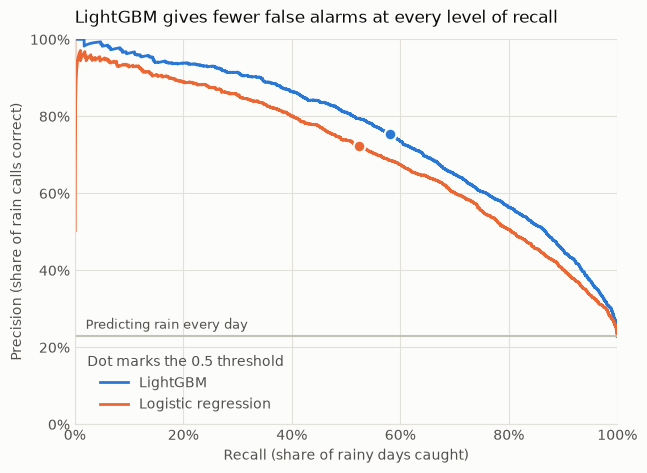

In [9]:
logreg_proba = logreg.predict_proba(X_val)[:, 1]
gbm_proba = gbm.predict_proba(X_val_gbm)[:, 1]

fig, ax = plt.subplots(figsize=(7, 5), facecolor=SURFACE)
for name, proba, colour in [('LightGBM', gbm_proba, BLUE), ('Logistic regression', logreg_proba, ORANGE)]:
    precision, recall, _ = precision_recall_curve(y_val, proba)
    ax.plot(recall, precision, color=colour, linewidth=2, label=name)
    at_half = (proba >= 0.5).astype(int)
    ax.scatter(recall_score(y_val, at_half), precision_score(y_val, at_half), s=70, color=colour,
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.axhline(y_val.mean(), color=GREY, linewidth=1.5)
ax.annotate('Predicting rain every day', (0.02, y_val.mean() + 0.02), color=MUTED, fontsize=9)
style(ax, 'LightGBM gives fewer false alarms at every level of recall')
ax.set_xlabel('Recall (share of rainy days caught)', color=MUTED)
ax.set_ylabel('Precision (share of rain calls correct)', color=MUTED)
ax.xaxis.set_major_formatter('{x:.0%}')
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc='lower left', labelcolor=MUTED, title='Dot marks the 0.5 threshold')
ax.get_legend().get_title().set_color(MUTED)
fig.savefig('../figures/precision_recall.png', dpi=200, bbox_inches='tight')
plt.show()


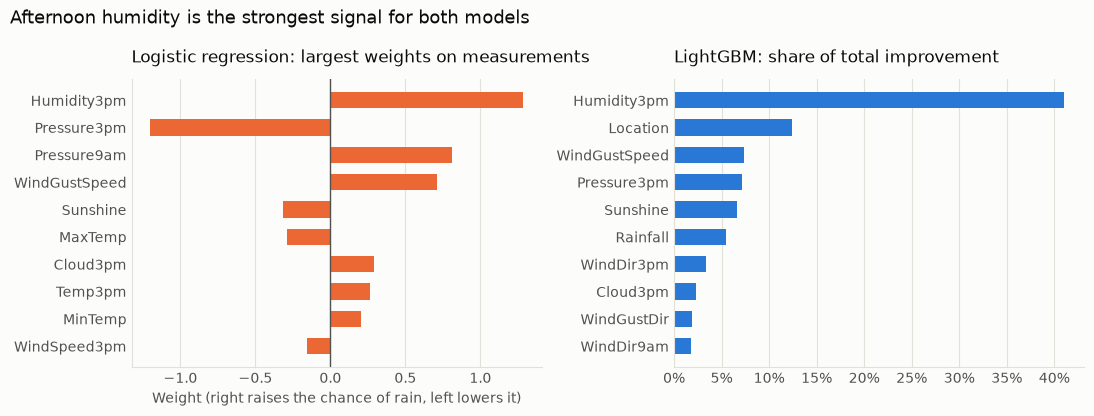

In [10]:
names = pd.Series(logreg['prep'].get_feature_names_out()).str.split('__').str[1]
coefs = pd.Series(logreg['model'].coef_[0], index=names)[num_cols]
top_coefs = coefs[coefs.abs().sort_values(ascending=False).index[:10]]

gain = pd.Series(gbm.booster_.feature_importance(importance_type='gain'), index=X_train_gbm.columns)
top_gain = (gain / gain.sum()).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=SURFACE)
axes[0].barh(top_coefs.index, top_coefs, color=ORANGE, height=0.6)
axes[0].axvline(0, color=MUTED, linewidth=1)
style(axes[0], 'Logistic regression: largest weights on measurements')
axes[0].set_xlabel('Weight (right raises the chance of rain, left lowers it)', color=MUTED)
axes[1].barh(top_gain.index, top_gain, color=BLUE, height=0.6)
style(axes[1], 'LightGBM: share of total improvement')
axes[1].xaxis.set_major_formatter('{x:.0%}')
for ax in axes:
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()
fig.suptitle('Afternoon humidity is the strongest signal for both models', x=0.01, ha='left', color=INK, fontsize=13)
fig.tight_layout()
fig.savefig('../figures/what_models_use.png', dpi=200, bbox_inches='tight')
plt.show()
